# Thực nghiệm lại Trans2Vec trên bộ dữ liệu `food`

**Bài báo:** *Trans2Vec: Learning Transaction Embedding via Items and Frequent Itemsets*
(D. Nguyen, T.D. Nguyen, W. Luo, S. Venkatesh, PAKDD 2018).
Code và dữ liệu gốc: https://github.com/nphdang/Trans2Vec

**Mục tiêu:** chạy lại thí nghiệm phân loại giao dịch yes/no của tác giả trên bộ `food` và so sánh với số trong bài báo.

**Thiết lập giống code gốc** (`codes/trans2vec_*_classify.py`):
- Doc2Vec **PV-DBOW** (`dm=0`), 128 chiều, `min_count=0`, 50 epoch
- Bộ phân loại **LinearSVC** (tham số mặc định)
- Chia cố định: **3200 giao dịch đầu để train, 800 cuối để test**
- Mỗi phương pháp chạy **10 lần**, báo trung bình ± độ lệch chuẩn của accuracy, micro-F1, macro-F1

## 1. Thư viện và cấu hình

Các tham số khai báo một chỗ, giống hệt code gốc của tác giả, để sau muốn đổi chỉ cần sửa ở đây.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tìm thư mục dự án office-lunch: đi ngược lên từ thư mục đang chạy cho tới khi thấy pipeline/data/food.txt
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline" / "data" / "food.txt").exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        f"Không tìm thấy pipeline/data/food.txt khi đi lên từ {Path.cwd()}. "
        "Hãy mở notebook bằng Jupyter hoặc VS Code chạy trên máy, với kernel .venv của dự án."
    )

DATA = ROOT / "pipeline" / "data"   # dữ liệu food
OUT = ROOT / "pipeline" / "out"     # nơi lưu kết quả
OUT.mkdir(exist_ok=True)

# Thiết lập giống code gốc của tác giả
DIM = 128        # số chiều vector
EPOCHS = 50      # số vòng train Doc2Vec
N_TRAIN = 3200   # 3200 giao dịch đầu để train, 800 cuối để test
N_RUNS = 10      # chạy 10 lần lấy trung bình

print("Thư mục dự án:", ROOT)
print("Dữ liệu:", DATA)

Thư mục dự án: /Users/huyhd/Huy Form/University/CSDL/Project/office-lunch
Dữ liệu: /Users/huyhd/Huy Form/University/CSDL/Project/office-lunch/pipeline/data


## 2. Đọc dữ liệu và thống kê mô tả

`food.txt` có 4000 dòng, mỗi dòng là một giao dịch: `nhãn<TAB>mã món mã món ...` (nhãn là `yes` hoặc `no`).
Hàm `load` đọc file theo đúng cách của hàm `load_items` trong code gốc.

,Giá trị
Số giao dịch,4000
Số món khác nhau,1559
Nhãn yes / no,2000 / 2000
Train yes / no,1602 / 1598
Test yes / no,398 / 402
Độ dài TB / min / max,26.6 / 3 / 262
Giao dịch có món lặp lại,991


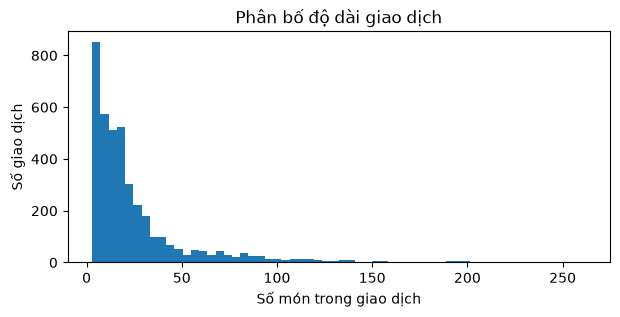

In [2]:
def load(path):
    """Đọc file dạng 'nhãn<TAB>token token ...' giống hàm load_items của code gốc."""
    X, y = [], []
    for line in open(path, encoding="utf-8"):
        label, content = line.split("\t")
        if content != "\n":
            y.append(label)
            X.append(content.rstrip().split(" "))
    return X, np.array(y)


items_X, y = load(DATA / "food.txt")

lengths = np.array([len(t) for t in items_X])
stats = pd.Series({
    "Số giao dịch": len(items_X),
    "Số món khác nhau": len({i for t in items_X for i in t}),
    "Nhãn yes / no": f"{(y == 'yes').sum()} / {(y == 'no').sum()}",
    "Train yes / no": f"{(y[:N_TRAIN] == 'yes').sum()} / {(y[:N_TRAIN] == 'no').sum()}",
    "Test yes / no": f"{(y[N_TRAIN:] == 'yes').sum()} / {(y[N_TRAIN:] == 'no').sum()}",
    "Độ dài TB / min / max": f"{lengths.mean():.1f} / {lengths.min()} / {lengths.max()}",
    "Giao dịch có món lặp lại": int(sum(len(t) != len(set(t)) for t in items_X)),
})
display(stats.to_frame("Giá trị"))

plt.figure(figsize=(7, 3))
plt.hist(lengths, bins=60)
plt.xlabel("Số món trong giao dịch")
plt.ylabel("Số giao dịch")
plt.title("Phân bố độ dài giao dịch")
plt.show()

**Nhận xét** (điền sau khi chạy):
- Dữ liệu cân bằng: … yes / … no; tập train và test cũng gần cân bằng.
- Phân bố độ dài lệch phải: phần lớn giao dịch ngắn, một số ít rất dài (tối đa … món).
- Có … giao dịch chứa món lặp lại; file `food_items_fis_*` của tác giả đã bỏ trùng các món này.